In [2]:
import sys
import pandas as pd
import torch
import torch.nn as nn

# Pour rendre plus large l'affichage Pandas
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# Chemin vers les scripts
sys.path.append("../src/")
sys.path.append("../models/")

from src.preprocess import load_and_filter_data, train_val_test_split, prepare_datasets, numpy_to_torch
from src.train import train_model
from src.evaluate import predict, compute_metrics
from src.visualization import plot_loss, plot_predictions_compare, plot_prediction_lstm, barplot_metrics

from models.lstm_model import LSTMModel
from models.gru_model import GRUModel
from models.attention_model import AttentionModel

device = torch.device("cuda")
print("Device utilisé:", device)

Device utilisé: cuda


Aperçu df :
                 close
date                  
2015-01-01  314.248993
2015-01-02  315.032013
2015-01-03  281.082001
2015-01-04  264.195007
2015-01-05  274.473999
Shape : (3732, 1)


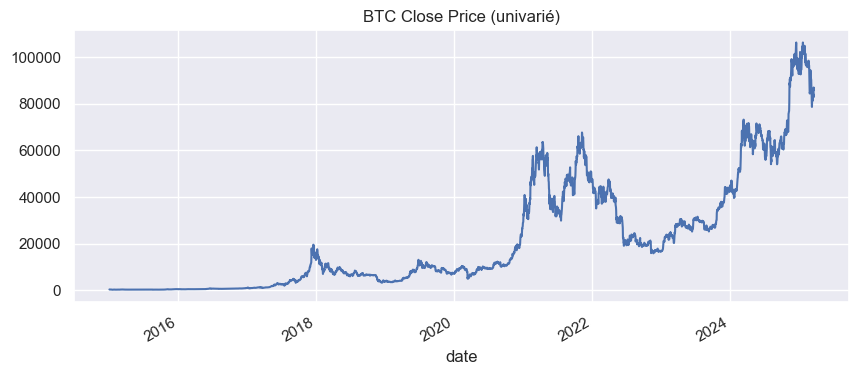

In [3]:
csv_path = "data\BTC.csv"
df = load_and_filter_data(csv_path)

print("Aperçu df :")
print(df.head())
print("Shape :", df.shape)

df['close'].plot(title="BTC Close Price (univarié)", figsize=(10,4))
plt.show()


In [4]:
# Split
df_train, df_val, df_test = train_val_test_split(df, 0.8, 0.1)
print("Train set size:", len(df_train))
print("Val set size:  ", len(df_val))
print("Test set size: ", len(df_test))

Train set size: 2985
Val set size:   373
Test set size:  374


In [5]:
window_size = 30
horizons = [1,3,7]

datasets = {}
for h in horizons:
    X_train, y_train, X_val, y_val, X_test, y_test, scaler = prepare_datasets(
        df_train, df_val, df_test, 
        window_size=window_size, horizon=h
    )
    datasets[h] = {
        'X_train': X_train,
        'y_train': y_train,
        'X_val':   X_val,
        'y_val':   y_val,
        'X_test':  X_test,
        'y_test':  y_test,
        'scaler':  scaler
    }

In [6]:
import json
import torch
import torch.nn as nn

lstm_config_path = r"LSTM\config.json"
lstm_weights_path = r"LSTM\pytorch_model.bin"

with open(lstm_config_path, 'r') as f:
    config_lstm = json.load(f)

print("Config LSTM pré-entraîné:", config_lstm)

pretrained_lstm = LSTMModel(
    input_dim=config_lstm["input_dim"],   # ex: 1
    hidden_dim=config_lstm["hidden_dim"],
    num_layers=config_lstm["num_layers"],
    output_dim=config_lstm["output_dim"]
)

# Charger le checkpoint (sauvegardé avec input_dim=1)
state_dict = torch.load(lstm_weights_path, map_location='cpu')
pretrained_lstm.load_state_dict(state_dict)
pretrained_lstm.eval()
print("LSTM pré-entraîné chargé avec succès.")

Config LSTM pré-entraîné: {'input_dim': 1, 'hidden_dim': 64, 'num_layers': 5, 'output_dim': 1, 'num_epochs': 500}
LSTM pré-entraîné chargé avec succès.



=== Résultats finaux ===
             Model  Horizon           MAE          RMSE       MAPE        R2
0              GRU        1   4739.243164   6564.452452   5.419070  0.833770
1        Attention        1   4577.134766   6692.364007   5.164821  0.827229
2              GRU        3   6088.290039   7978.382292   7.171141  0.755587
3        Attention        3  11990.716797  18441.460246  13.138130 -0.305826
4              GRU        7   8317.857422  11032.669305   9.679302  0.535255
5        Attention        7  12102.265625  15758.643089  14.048198  0.051819
6  LSTM_pretrained        1   8008.228237  11715.077978   8.861797  0.470578
7  LSTM_pretrained        3   8439.195729  11917.083952   9.515506  0.454701
8  LSTM_pretrained        7   9039.624767  12294.676638  10.377987  0.422852


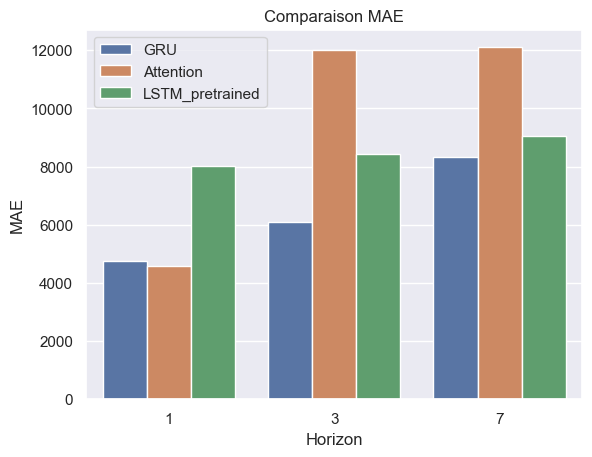

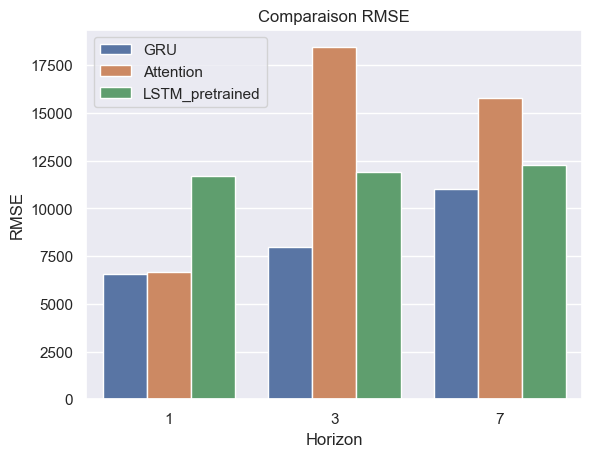

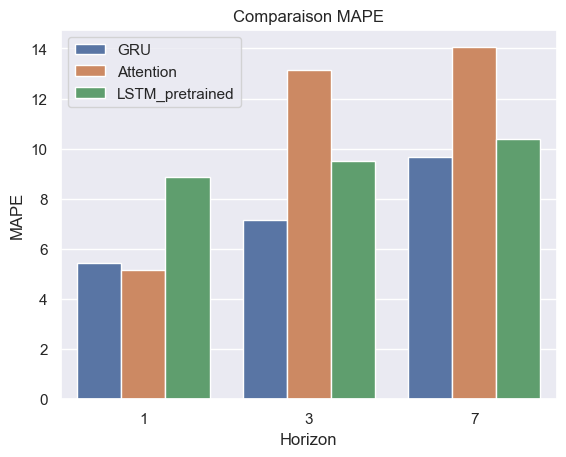

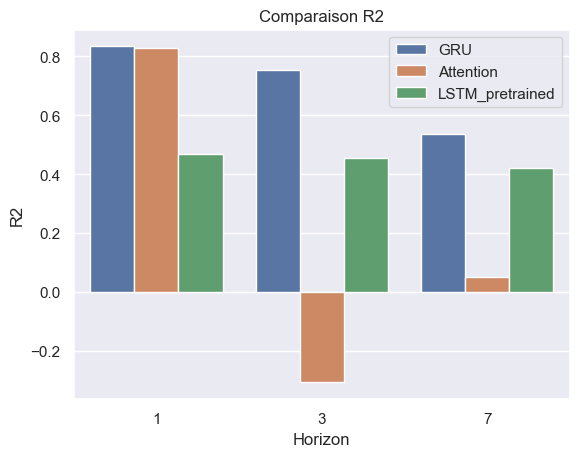

In [13]:
df_results = pd.DataFrame(results)
print("\n=== Résultats finaux ===")
print(df_results)

barplot_metrics(df_results)

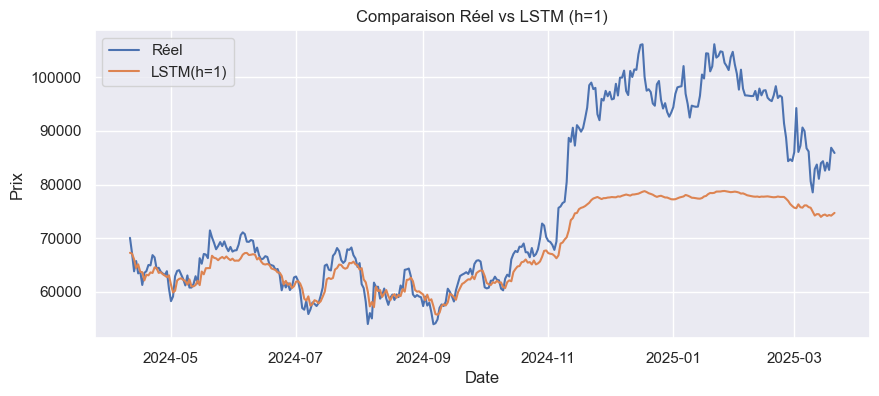

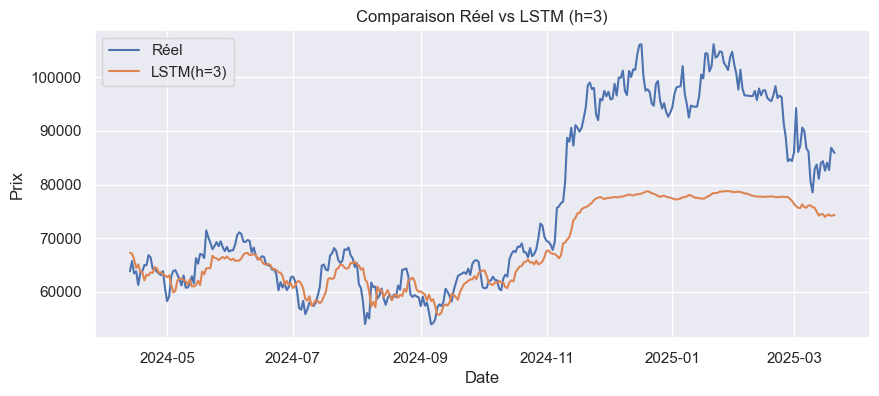

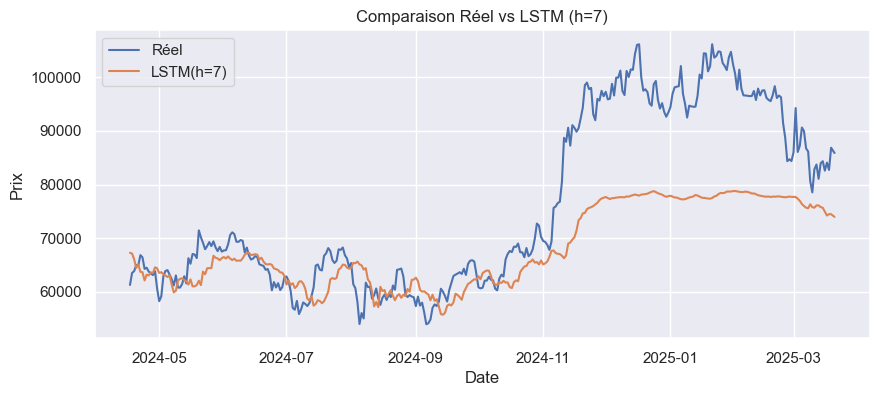

In [ ]:
for horizon in horizons:
    data_h = datasets[horizon]
    X_test, y_test = data_h['X_test'], data_h['y_test']
    scaler = data_h['scaler']
    
    X_test_t, y_test_t = numpy_to_torch(X_test, y_test)
    test_ds = torch.utils.data.TensorDataset(X_test_t, y_test_t)
    test_loader = torch.utils.data.DataLoader(test_ds, batch_size=32, shuffle=False)
    
    lstm_preds, lstm_trues = predict(pretrained_lstm, test_loader)
    
    # On inverse transform
    def inverse_transform(preds, trues):
        nb_feats = 5
        arr_pred = np.zeros((len(preds), nb_feats))
        arr_true = np.zeros((len(trues), nb_feats))
        close_idx = list(df_train.columns).index('close')
        arr_pred[:, close_idx] = preds.ravel()
        arr_true[:, close_idx] = trues.ravel()
        
        inv_pred = scaler.inverse_transform(arr_pred)[:, close_idx]
        inv_true = scaler.inverse_transform(arr_true)[:, close_idx]
        return inv_pred, inv_true
    
    lstm_pred_inv, lstm_true_inv = inverse_transform(lstm_preds, lstm_trues)
    lstm_metrics = compute_metrics(lstm_pred_inv.reshape(-1,1), lstm_true_inv.reshape(-1,1))
    
    results.append({"Model":"LSTM_pretrained", "Horizon":horizon, **lstm_metrics})
    
    # Plot
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(lstm_pred_inv):
        plot_prediction_lstm(test_dates, lstm_true_inv, lstm_pred_inv, horizon)


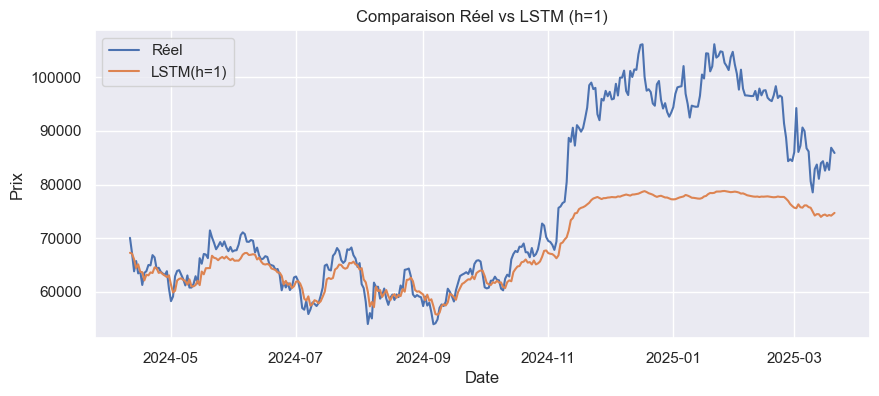

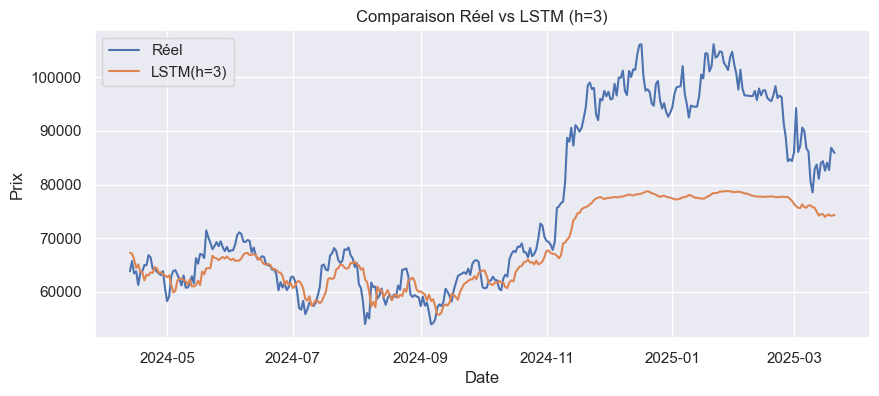

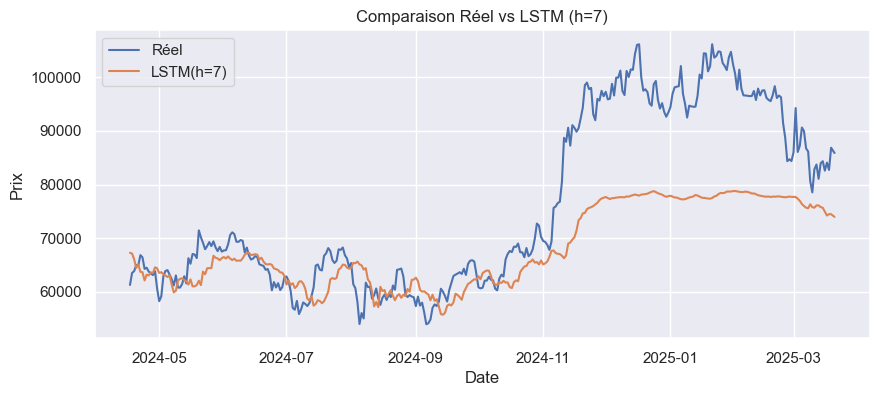

In [ ]:
for horizon in horizons:
    data_h = datasets[horizon]
    X_test, y_test = data_h['X_test'], data_h['y_test']
    scaler = data_h['scaler']
    
    X_test_t, y_test_t = numpy_to_torch(X_test, y_test)
    test_ds = torch.utils.data.TensorDataset(X_test_t, y_test_t)
    test_loader = torch.utils.data.DataLoader(test_ds, batch_size=32, shuffle=False)
    
    lstm_preds, lstm_trues = predict(pretrained_lstm, test_loader)
    
    # On inverse transform
    def inverse_transform(preds, trues):
        nb_feats = 5
        arr_pred = np.zeros((len(preds), nb_feats))
        arr_true = np.zeros((len(trues), nb_feats))
        close_idx = list(df_train.columns).index('close')
        arr_pred[:, close_idx] = preds.ravel()
        arr_true[:, close_idx] = trues.ravel()
        
        inv_pred = scaler.inverse_transform(arr_pred)[:, close_idx]
        inv_true = scaler.inverse_transform(arr_true)[:, close_idx]
        return inv_pred, inv_true
    
    lstm_pred_inv, lstm_true_inv = inverse_transform(lstm_preds, lstm_trues)
    lstm_metrics = compute_metrics(lstm_pred_inv.reshape(-1,1), lstm_true_inv.reshape(-1,1))
    
    results.append({"Model":"LSTM_pretrained", "Horizon":horizon, **lstm_metrics})
    
    # Plot
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(lstm_pred_inv):
        plot_prediction_lstm(test_dates, lstm_true_inv, lstm_pred_inv, horizon)


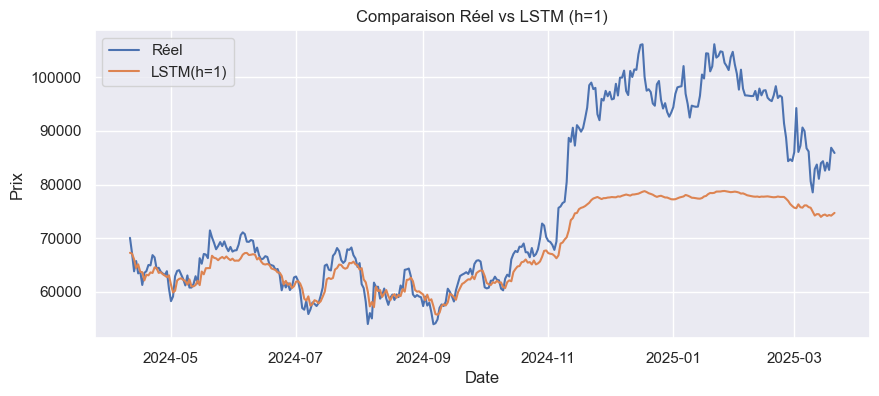

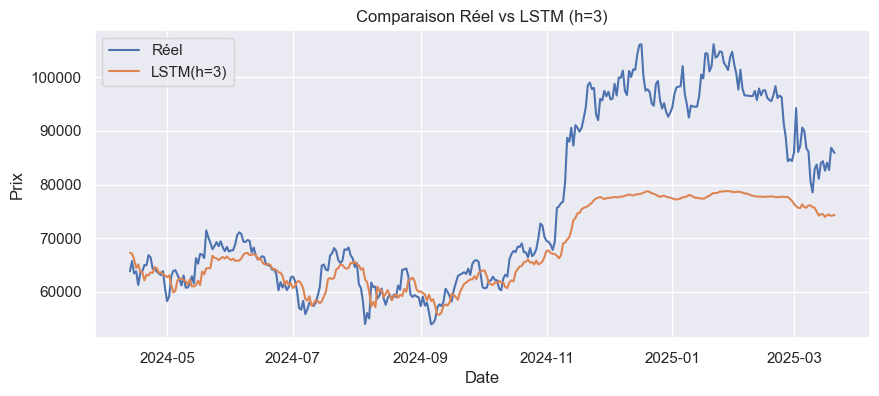

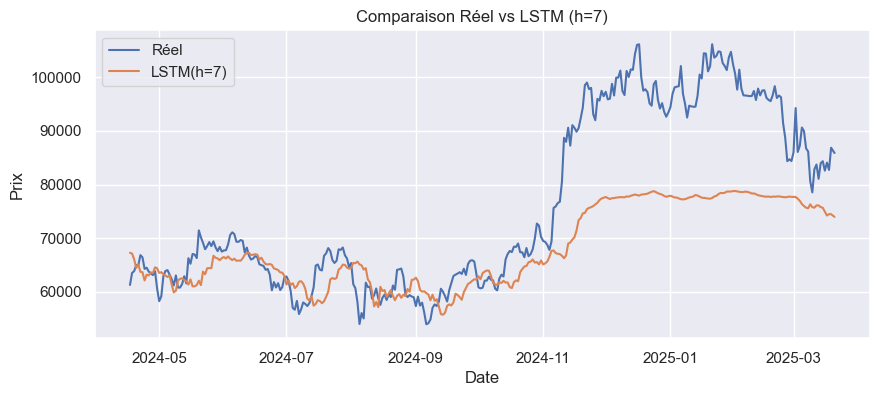

In [ ]:
for horizon in horizons:
    data_h = datasets[horizon]
    X_test, y_test = data_h['X_test'], data_h['y_test']
    scaler = data_h['scaler']
    
    X_test_t, y_test_t = numpy_to_torch(X_test, y_test)
    test_ds = torch.utils.data.TensorDataset(X_test_t, y_test_t)
    test_loader = torch.utils.data.DataLoader(test_ds, batch_size=32, shuffle=False)
    
    lstm_preds, lstm_trues = predict(pretrained_lstm, test_loader)
    
    # On inverse transform
    def inverse_transform(preds, trues):
        nb_feats = 5
        arr_pred = np.zeros((len(preds), nb_feats))
        arr_true = np.zeros((len(trues), nb_feats))
        close_idx = list(df_train.columns).index('close')
        arr_pred[:, close_idx] = preds.ravel()
        arr_true[:, close_idx] = trues.ravel()
        
        inv_pred = scaler.inverse_transform(arr_pred)[:, close_idx]
        inv_true = scaler.inverse_transform(arr_true)[:, close_idx]
        return inv_pred, inv_true
    
    lstm_pred_inv, lstm_true_inv = inverse_transform(lstm_preds, lstm_trues)
    lstm_metrics = compute_metrics(lstm_pred_inv.reshape(-1,1), lstm_true_inv.reshape(-1,1))
    
    results.append({"Model":"LSTM_pretrained", "Horizon":horizon, **lstm_metrics})
    
    # Plot
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(lstm_pred_inv):
        plot_prediction_lstm(test_dates, lstm_true_inv, lstm_pred_inv, horizon)


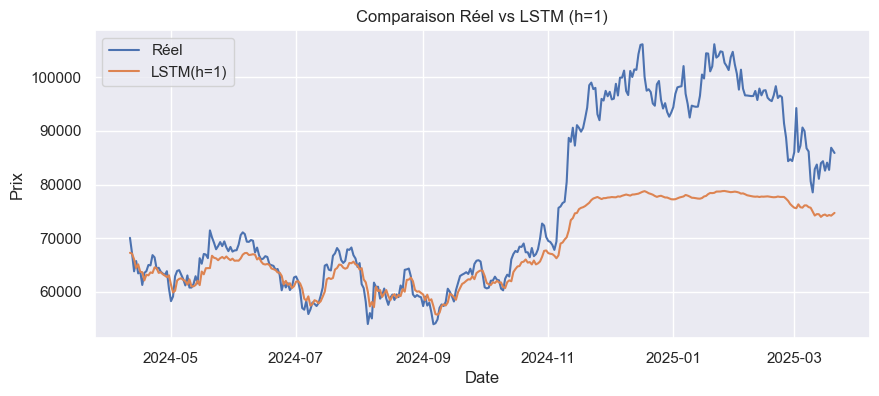

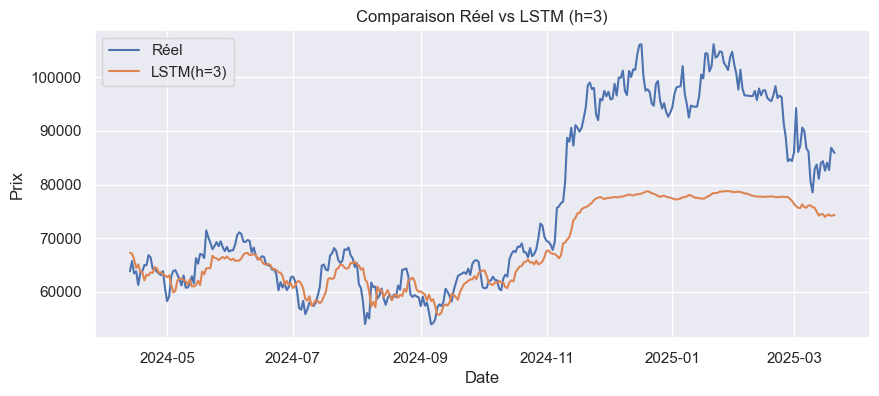

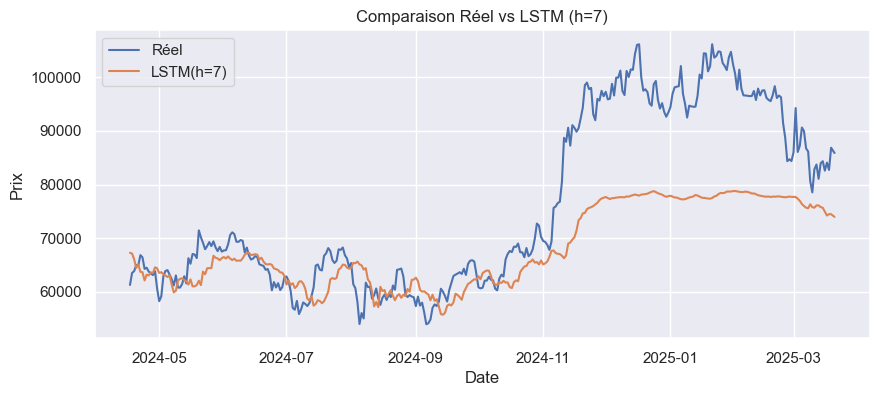

In [ ]:
for horizon in horizons:
    data_h = datasets[horizon]
    X_test, y_test = data_h['X_test'], data_h['y_test']
    scaler = data_h['scaler']
    
    X_test_t, y_test_t = numpy_to_torch(X_test, y_test)
    test_ds = torch.utils.data.TensorDataset(X_test_t, y_test_t)
    test_loader = torch.utils.data.DataLoader(test_ds, batch_size=32, shuffle=False)
    
    lstm_preds, lstm_trues = predict(pretrained_lstm, test_loader)
    
    # On inverse transform
    def inverse_transform(preds, trues):
        nb_feats = 5
        arr_pred = np.zeros((len(preds), nb_feats))
        arr_true = np.zeros((len(trues), nb_feats))
        close_idx = list(df_train.columns).index('close')
        arr_pred[:, close_idx] = preds.ravel()
        arr_true[:, close_idx] = trues.ravel()
        
        inv_pred = scaler.inverse_transform(arr_pred)[:, close_idx]
        inv_true = scaler.inverse_transform(arr_true)[:, close_idx]
        return inv_pred, inv_true
    
    lstm_pred_inv, lstm_true_inv = inverse_transform(lstm_preds, lstm_trues)
    lstm_metrics = compute_metrics(lstm_pred_inv.reshape(-1,1), lstm_true_inv.reshape(-1,1))
    
    results.append({"Model":"LSTM_pretrained", "Horizon":horizon, **lstm_metrics})
    
    # Plot
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(lstm_pred_inv):
        plot_prediction_lstm(test_dates, lstm_true_inv, lstm_pred_inv, horizon)
